PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import linear regression model
from sklearn.linear_model import LinearRegression
from tqdm import tqdm
from statsmodels.tsa.holtwinters import Holt

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [ ]:
roster_df = pd.read_csv(localized_url('/Users/yarkin/Desktop/Dissertation/statistical-analysis-and-modeling-of-football-data/Understat/Data/understat_roster_1524.csv'))


In [ ]:
match_df = pd.read_csv(localized_url('/Users/yarkin/Desktop/Dissertation/statistical-analysis-and-modeling-of-football-data/Understat/Data/understat_match_1524.csv'))


In [146]:
match_df.columns

Index(['id', 'fid', 'h', 'a', 'date', 'league_id', 'season', 'h_goals',
       'a_goals', 'team_h', 'team_a', 'h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
       'league', 'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda'],
      dtype='object')

In [147]:
roster_df.drop(columns=['id','roster_in','roster_out'], inplace=True)

In [148]:
def extract_id_from_link(df):
    # Extract player ID from the link
    df['id'] = df['match_link'].str.extract(r'(\d+)$').astype(int)
    return df


In [149]:
roster_df= extract_id_from_link(roster_df)

In [150]:
roster_df

,goals,own_goals,shots,xG,time,player_id,team_id,position,player,h_a,yellow_card,red_card,key_passes,assists,xA,xGChain,xGBuildup,positionOrder,match_link,id
0,0,0,0,0.000000,90,560,89,GK,Sergio Romero,h,0,0,0,0,0.000000,0.000000,0.000000,1,https://understat.com/match/81,81
1,0,0,0,0.000000,82,557,89,DR,Matteo Darmian,h,0,0,1,0,0.106513,0.106513,0.106513,2,https://understat.com/match/81,81
2,0,0,0,0.000000,90,628,89,DC,Chris Smalling,h,0,0,0,0,0.000000,0.106513,0.106513,3,https://understat.com/match/81,81
3,0,0,0,0.000000,90,548,89,DC,Daley Blind,h,0,0,0,0,0.000000,0.127738,0.127738,3,https://understat.com/match/81,81
4,0,0,0,0.000000,90,1006,89,DL,Luke Shaw,h,0,0,0,0,0.000000,0.021225,0.021225,4,https://understat.com/match/81,81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96086,0,0,1,0.113749,9,7198,82,Sub,Oliver Skipp,a,0,0,0,0,0.000000,0.113749,0.000000,17,https://understat.com/match/22274,22274
96087,0,0,0,0.000000,9,7430,82,Sub,Emerson,a,0,0,0,0,0.000000,0.067532,0.067532,17,https://understat.com/match/22274,22274
96088,0,0,0,0.000000,1,9332,82,Sub,Dane Scarlett,a,0,0,0,0,0.000000,0.000000,0.000000,17,https://understat.com/match/22274,22274
96089,0,0,1,0.046925,19,343,82,Sub,Pierre-Emile Højbjerg,a,0,0,0,0,0.000000,0.901846,0.901846,17,https://understat.com/match/22274,22274


In [151]:
roster_df=pd.merge(roster_df, match_df[['id', 'date']], on='id', how='left')

In [152]:
roster_df

,goals,own_goals,shots,xG,time,player_id,team_id,position,player,h_a,...,red_card,key_passes,assists,xA,xGChain,xGBuildup,positionOrder,match_link,id,date
0,0,0,0,0.000000,90,560,89,GK,Sergio Romero,h,...,0,0,0,0.000000,0.000000,0.000000,1,https://understat.com/match/81,81,2015-08-08 15:45:00
1,0,0,0,0.000000,82,557,89,DR,Matteo Darmian,h,...,0,1,0,0.106513,0.106513,0.106513,2,https://understat.com/match/81,81,2015-08-08 15:45:00
2,0,0,0,0.000000,90,628,89,DC,Chris Smalling,h,...,0,0,0,0.000000,0.106513,0.106513,3,https://understat.com/match/81,81,2015-08-08 15:45:00
3,0,0,0,0.000000,90,548,89,DC,Daley Blind,h,...,0,0,0,0.000000,0.127738,0.127738,3,https://understat.com/match/81,81,2015-08-08 15:45:00
4,0,0,0,0.000000,90,1006,89,DL,Luke Shaw,h,...,0,0,0,0.000000,0.021225,0.021225,4,https://understat.com/match/81,81,2015-08-08 15:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96086,0,0,1,0.113749,9,7198,82,Sub,Oliver Skipp,a,...,0,0,0,0.000000,0.113749,0.000000,17,https://understat.com/match/22274,22274,2024-05-19 15:00:00
96087,0,0,0,0.000000,9,7430,82,Sub,Emerson,a,...,0,0,0,0.000000,0.067532,0.067532,17,https://understat.com/match/22274,22274,2024-05-19 15:00:00
96088,0,0,0,0.000000,1,9332,82,Sub,Dane Scarlett,a,...,0,0,0,0.000000,0.000000,0.000000,17,https://understat.com/match/22274,22274,2024-05-19 15:00:00
96089,0,0,1,0.046925,19,343,82,Sub,Pierre-Emile Højbjerg,a,...,0,0,0,0.000000,0.901846,0.901846,17,https://understat.com/match/22274,22274,2024-05-19 15:00:00


In [153]:
roster_df.columns

Index(['goals', 'own_goals', 'shots', 'xG', 'time', 'player_id', 'team_id',
       'position', 'player', 'h_a', 'yellow_card', 'red_card', 'key_passes',
       'assists', 'xA', 'xGChain', 'xGBuildup', 'positionOrder', 'match_link',
       'id', 'date'],
      dtype='object')

In [154]:
match_id_list = roster_df.id.unique().tolist()
player_id_list = roster_df.player_id.unique().tolist()
team_id_list = roster_df.team_id.unique().tolist()

In [155]:
features_to_aggregate = ['shots', 'xG', 'key_passes', 'xA', 'xGChain', 'xGBuildup', 'yellow_card', 'red_card']

In [ ]:
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.linear_model import LinearRegression

def aggregation_with_error_analysis(df, features_to_aggregate, window=5, discrete_features=None):
    """
    Aggregates player match data using:
    - Rolling mean
    - Linear regression
    - Exponential Moving Average (EMA)
    - Weighted Moving Average (WMA)
    - Median Aggregation
    Computes prediction error for each method vs actual value.
    """
    
    if discrete_features is None:
        discrete_features = ["shots", "key_passes", "yellow_card", "red_card"]

    df = df.copy()
    df = df.sort_values(by=['player_id', 'date'])
    df.reset_index(drop=True, inplace=True)

    methods = ['linear', 'mean', 'ExpoMovingAverage', 'WMA', 'median']

    # Prepare columns for predictions & errors
    for feature in features_to_aggregate:
        for method in methods:
            df[f'{feature}_{method}'] = np.nan
            df[f'{feature}_{method}_error'] = np.nan

    for player_id, player_df in tqdm(df.groupby('player_id'), desc="Aggregating players"):
        player_df = player_df.sort_values('date').copy()
        player_df.reset_index(drop=False, inplace=True)

        for feature in features_to_aggregate:
            preds = {method: [] for method in methods}
            errors = {method: [] for method in methods}

            for i in range(len(player_df)):
                player_df[feature]=player_df[feature]*(90/player_df['time'])
                actual = player_df.loc[i, feature]
                

                # Early-game handling
                if i == 0:
                    past_values = player_df.loc[:0, feature].astype(float)  # use actual value of first row
                elif i < window:
                    past_values = player_df.loc[:i-1, feature].astype(float)
                else:
                    past_values = player_df.loc[i - window:i - 1, feature].astype(float)

                # Handle empty past_values case
                if past_values.empty:
                    mean_val = expo_val = wma_val = median_val = linear_val = 0
                else:
                    mean_val = past_values.mean()
                    expo_val = past_values.ewm(span=window, adjust=False).mean().iloc[-1]
                    wma_val = np.dot(past_values, np.arange(1, len(past_values) + 1)) / np.sum(np.arange(1, len(past_values) + 1))
                    median_val = past_values.median()

                    # Linear regression if enough past data
                    if len(past_values) >= 2:  # at least 2 points for regression
                        X = np.arange(len(past_values)).reshape(-1, 1)
                        y = past_values.values
                        lin_model = LinearRegression().fit(X, y)
                        linear_val = lin_model.predict(np.array([[len(past_values)]]))[0]
                    else:
                        linear_val = mean_val

                # Apply rounding/clamping for discrete features
                if feature in discrete_features:
                    rounded_vals = {
                        'mean': max(0, round(mean_val)),
                        'linear': max(0, round(linear_val)),
                        'ExpoMovingAverage': max(0, round(expo_val)),
                        'WMA': max(0, round(wma_val)),
                        'median': max(0, round(median_val))
                    }
                else:
                    rounded_vals = {
                        'mean': max(0, mean_val),
                        'linear': max(0, linear_val),
                        'ExpoMovingAverage': max(0, expo_val),
                        'WMA': max(0, wma_val),
                        'median': max(0, median_val)
                    }

                # Store predictions & errors
                for method in methods:
                    preds[method].append(rounded_vals[method])
                    errors[method].append(abs(float(actual) - rounded_vals[method]))

            # Assign back to main DataFrame
            for method in methods:
                df.loc[player_df['index'], f'{feature}_{method}'] = preds[method]
                df.loc[player_df['index'], f'{feature}_{method}_error'] = errors[method]

    return df

In [179]:
def aggregation_with_error_analysis(
    df,
    features_to_aggregate,
    window=5,
    minutes_col="time",
    discrete_features=None,
    methods=("linear","mean","ExpoMovingAverage","WMA","median"),
    cap_minutes_at_90=True,
    shrink_low_minutes=True,
    shrink_floor_minutes=30,
):
    """
    Same outputs as the original:
      - <feature>_<method>
      - <feature>_<method>_error
    Internally computes on per-90, then converts back to raw for errors.
    """
    if discrete_features is None:
        discrete_features = ["shots", "key_passes", "yellow_card", "red_card"]

    # Work on a sorted copy; keep original index to align back later
    work = df.copy().sort_values(["player_id","date"]).reset_index()
    n = len(work)

    # Pre-allocate result arrays (write once at the end)
    results = {
        f"{f}_{m}": np.full(n, np.nan, dtype=float)
        for f in features_to_aggregate for m in methods
    }
    results.update({
        f"{f}_{m}_error": np.full(n, np.nan, dtype=float)
        for f in features_to_aggregate for m in methods
    })

    # Helper: effective minutes (cap and avoid /0)
    def effective_minutes(arr):
        arr = pd.to_numeric(arr, errors="coerce").fillna(0.0).to_numpy(dtype=float)
        if cap_minutes_at_90:
            arr = np.clip(arr, 0.0, 90.0)
        return arr

    for pid, g in tqdm(work.groupby("player_id", sort=False), desc="Aggregating players"):
        pos = g.index.to_numpy()
        mins = effective_minutes(g[minutes_col])
        mins_eff = np.where(mins > 0, mins, 1.0)
        to_per90 = 90.0 / mins_eff
        to_raw   = mins_eff / 90.0

        for f in features_to_aggregate:
            raw = pd.to_numeric(g[f], errors="coerce").fillna(0.0).to_numpy(dtype=float)
            per90 = raw * to_per90
            k = len(per90)

            # per-method containers
            pred_raw = {m: np.zeros(k, dtype=float) for m in methods}
            err_raw  = {m: np.zeros(k, dtype=float) for m in methods}

            for i in range(k):
                start = max(0, i - window)
                past = per90[start:i]  # strictly past

                if past.size == 0:
                    mean_val = median_val = expo_val = wma_val = linear_val = 0.0
                else:
                    mean_val = float(np.nanmean(past))
                    median_val = float(np.nanmedian(past))
                    # EMA
                    expo_val = float(pd.Series(past).ewm(span=window, adjust=False).mean().iloc[-1])
                    # WMA 1..n
                    w = np.arange(1, past.size + 1, dtype=float)
                    wma_val = float(np.dot(past, w) / w.sum())
                    # Linear via polyfit
                    if past.size >= 2:
                        x = np.arange(past.size, dtype=float)
                        slope, intercept = np.polyfit(x, past, 1)
                        linear_val = float(slope * past.size + intercept)
                    else:
                        linear_val = mean_val

                # Optional shrinkage for very low minutes to tame per90 spikes
                if shrink_low_minutes:
                    w_shrink = np.clip(mins[i] / max(shrink_floor_minutes, 1), 0.0, 1.0)
                    prior = mean_val
                    def S(x): return w_shrink * x + (1.0 - w_shrink) * prior
                else:
                    def S(x): return x

                per90_candidates = {
                    "mean": S(mean_val),
                    "median": S(median_val),
                    "ExpoMovingAverage": S(expo_val),
                    "WMA": S(wma_val),
                    "linear": S(linear_val),
                }

                for m in methods:
                    p = max(0.0, per90_candidates[m])      # per-90 prediction
                    r = max(0.0, p * to_raw[i])            # back to raw for this match's minutes
                    if f in discrete_features:
                        r = round(r)
                    pred_raw[m][i] = r
                    err_raw[m][i]  = abs(raw[i] - r)

            # write into results for this group slice
            for m in methods:
                results[f"{f}_{m}"][pos] = pred_raw[m]
                results[f"{f}_{m}_error"][pos] = err_raw[m]

    # Build results frame once and align to original order
    res_df = pd.DataFrame(results, index=work.index)
    res_df.index = work["index"]      # back to original indices
    res_df = res_df.reindex(df.index)

    return pd.concat([df, res_df], axis=1)

In [186]:
aggregated_df = aggregation_with_error_analysis(roster_df, features_to_aggregate, window=5)
aggregated_df

Aggregating players:   2%|▏         | 44/1763 [00:03<02:04, 13.78it/s]


KeyboardInterrupt: 

In [187]:
aggregated_df.columns

Index(['goals', 'own_goals', 'shots', 'xG', 'time', 'player_id', 'team_id',
       'position', 'player', 'h_a',
       ...
       'yellow_card_linear_error', 'yellow_card_mean_error',
       'yellow_card_ExpoMovingAverage_error', 'yellow_card_WMA_error',
       'yellow_card_median_error', 'red_card_linear_error',
       'red_card_mean_error', 'red_card_ExpoMovingAverage_error',
       'red_card_WMA_error', 'red_card_median_error'],
      dtype='object', length=101)

In [188]:
methods = ['mean', 'linear', 'ExpoMovingAverage', 'WMA', 'median']

In [189]:
errors_methods = [f'{feature}_{method}_error' for feature in features_to_aggregate for method in methods]
errors_df=aggregated_df[errors_methods].mean().reset_index().sort_values(by=["index"]).reset_index(drop=True)

errors_df


,index,0
0,key_passes_ExpoMovingAverage_error,0.732493
1,key_passes_WMA_error,0.736115
2,key_passes_linear_error,0.940785
3,key_passes_mean_error,0.729715
4,key_passes_median_error,0.620828
5,red_card_ExpoMovingAverage_error,0.009501
6,red_card_WMA_error,0.009762
7,red_card_linear_error,0.015974
8,red_card_mean_error,0.009553
9,red_card_median_error,0.004454


In [190]:
aggregated_df[(aggregated_df['red_card_WMA_error'] == 1) & (aggregated_df['red_card'] == 0)]

,goals,own_goals,shots,xG,time,player_id,team_id,position,player,h_a,...,yellow_card_linear_error,yellow_card_mean_error,yellow_card_ExpoMovingAverage_error,yellow_card_WMA_error,yellow_card_median_error,red_card_linear_error,red_card_mean_error,red_card_ExpoMovingAverage_error,red_card_WMA_error,red_card_median_error
934,0,0,0,0.000000,90,680,80,GK,Thibaut Courtois,h,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0
1118,0,0,1,0.103022,90,917,80,DC,John Terry,a,...,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0,0.0
1366,0,0,5,0.435375,90,764,86,DR,Daryl Janmaat,a,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0
1560,0,0,0,0.000000,90,527,81,GK,Adrián,a,...,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,1.0,0.0
1638,0,0,10,0.750782,90,488,87,AMC,Philippe Coutinho,h,...,0.0,0.0,0.0,0.0,0.0,2.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94114,0,0,0,0.000000,90,985,238,DC,Mason Holgate,a,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,0.0
94127,0,0,1,0.030850,90,8973,92,DR,Lorenz Assignon,h,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
94922,0,0,1,0.034340,79,7187,244,DL,Sergio Reguilón,a,...,1.0,1.0,1.0,1.0,1.0,0.0,2.0,2.0,1.0,0.0
95025,0,0,1,0.062727,88,6850,249,DC,Willy Boly,h,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0


In [191]:
import re
# Find the minimum error method for each feature
errors_df['feature'] = errors_df['index'].apply(lambda x: re.search(r'(\w+)_\w+_error', x).group(1) if re.search(r'(\w+)_\w+_error', x) else None)


In [192]:
errors_df.groupby('feature').apply(lambda x: x.loc[x[0].idxmin()]).reset_index(drop=True)[['feature', 'index', 0]] \
    .rename(columns={'index': 'min_error_method', 0: 'min_error_value'}) \
    .sort_values(by='feature')

/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_91461/4027762064.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  errors_df.groupby('feature').apply(lambda x: x.loc[x[0].idxmin()]).reset_index(drop=True)[['feature', 'index', 0]] \


,feature,min_error_method,min_error_value
0,key_passes,key_passes_median_error,0.620828
1,red_card,red_card_median_error,0.004454
2,shots,shots_median_error,0.756356
3,xA,xA_median_error,0.076377
4,xG,xG_median_error,0.100353
5,xGBuildup,xGBuildup_median_error,0.158708
6,xGChain,xGChain_median_error,0.235217
7,yellow_card,yellow_card_median_error,0.137339


In [193]:
aggregated_df[['key_passes']].describe()

,key_passes
count,96091.000000
mean,0.671665
std,1.055978
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,12.000000


In [194]:
features_to_aggregate = ['shots', 'xG', 'key_passes', 'xA', 'xGChain', 'xGBuildup', 'yellow_card', 'red_card']
methods = ['mean', 'linear', 'ExpoMovingAverage', 'WMA', 'median']

In [195]:
def error_analysis(df, features_to_aggregate, methods):
    """
    Computes mean absolute error per feature/method combination.

    This version is underscore-safe, works regardless of underscores in feature names,
    and ensures all features in features_to_aggregate are preserved in the output.
    """
    errors_methods = [
        f"{feature}_{method}_error"
        for feature in features_to_aggregate
        for method in methods
        if f"{feature}_{method}_error" in df.columns
    ]

    if not errors_methods:
        raise ValueError("No matching error columns found in DataFrame.")

    # Calculate mean errors
    errors_df = df[errors_methods].mean().reset_index()
    errors_df.columns = ["method_feature", "mean_error"]

    # Extract feature and method safely by splitting from the end
    errors_df["feature"] = errors_df["method_feature"].apply(
        lambda x: "_".join(x.split("_")[:-2])
    )
    errors_df["method"] = errors_df["method_feature"].apply(
        lambda x: x.split("_")[-2]
    )

    # Filter only for requested features to avoid stray values
    errors_df = errors_df[errors_df["feature"].isin(features_to_aggregate)]

    return errors_df[["feature", "method", "mean_error"]]


In [196]:

# --- Run aggregation for multiple windows ---
aggregated_dfs = {}
for window in tqdm(range(3, 30), desc="Aggregating for windows size:"):  # Windows 3 to 7
    aggregated = aggregation_with_error_analysis(roster_df, features_to_aggregate, window=window)
    aggregated_dfs[window] = aggregated





Aggregating for windows size:: 100%|██████████| 27/27 [38:34<00:00, 85.74s/it]


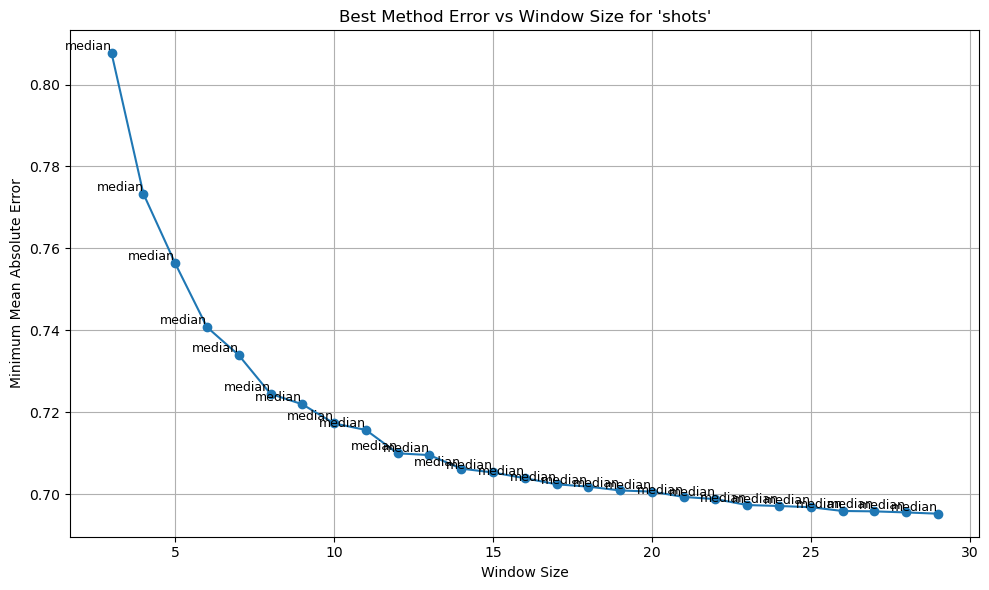

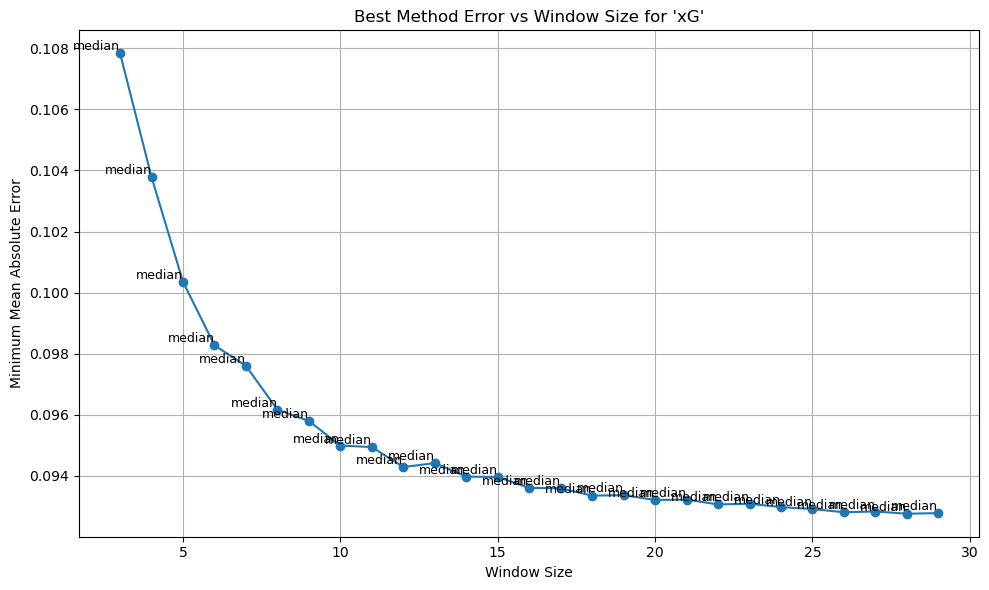

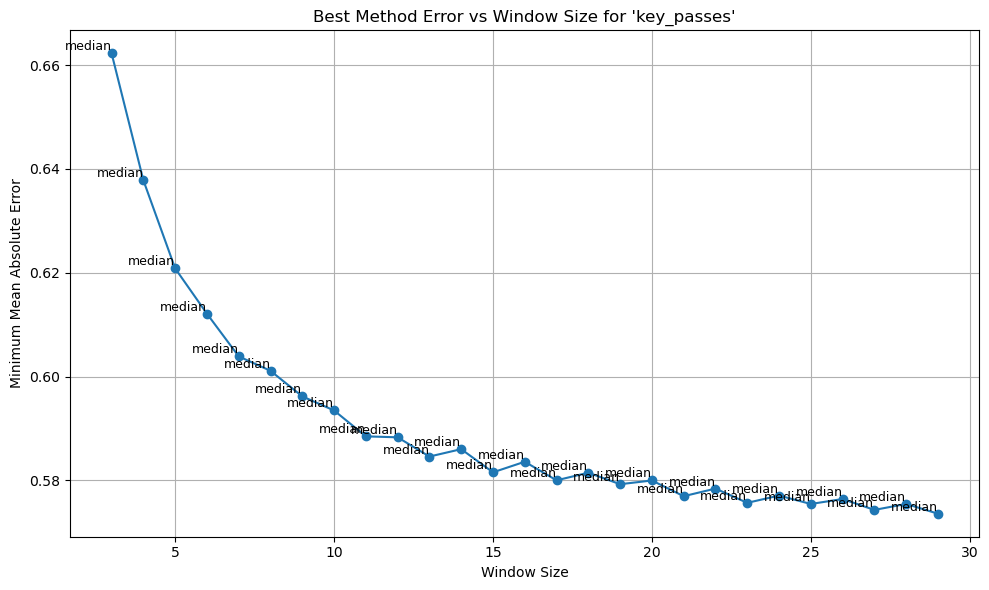

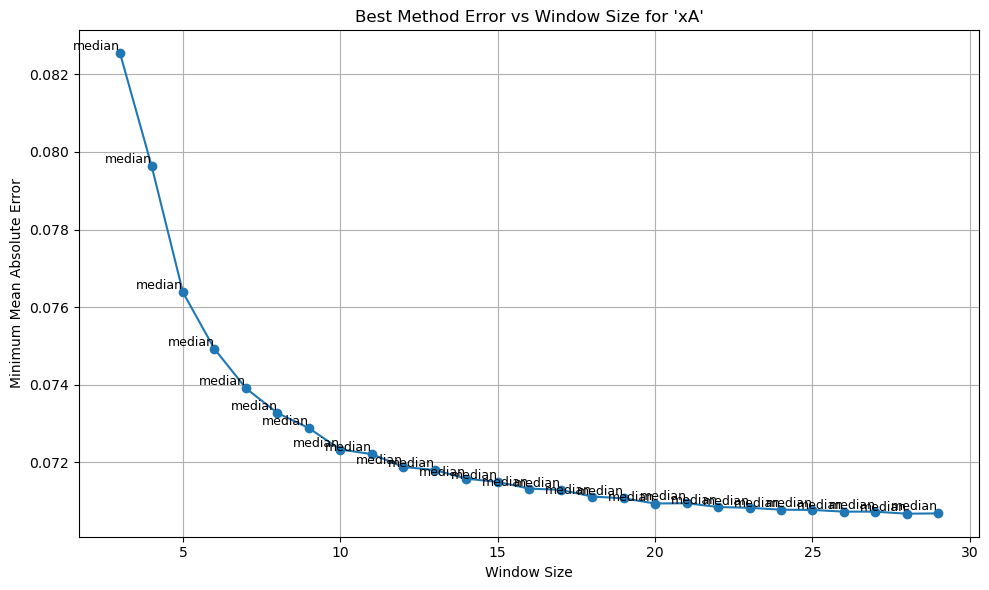

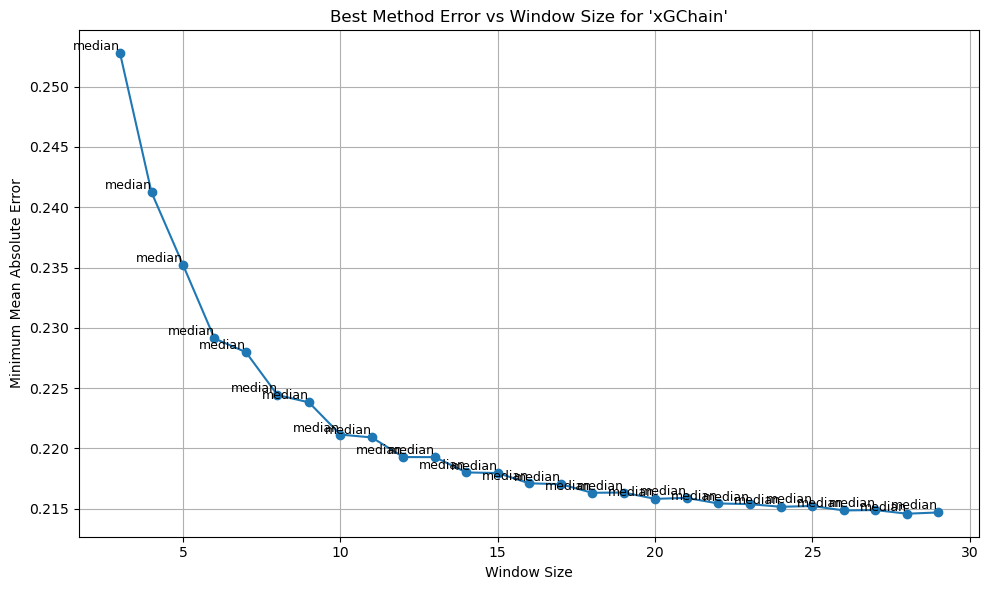

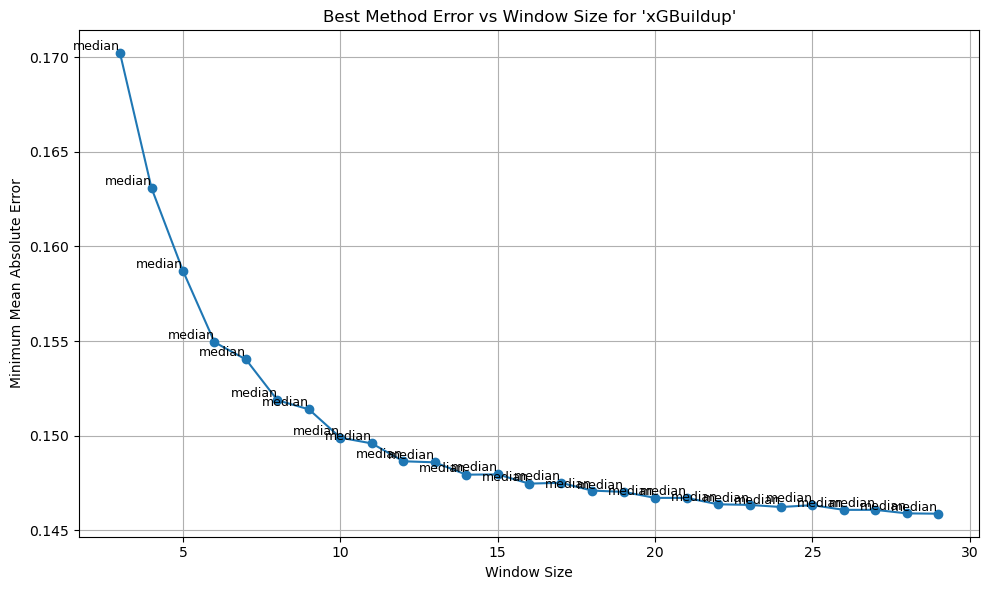

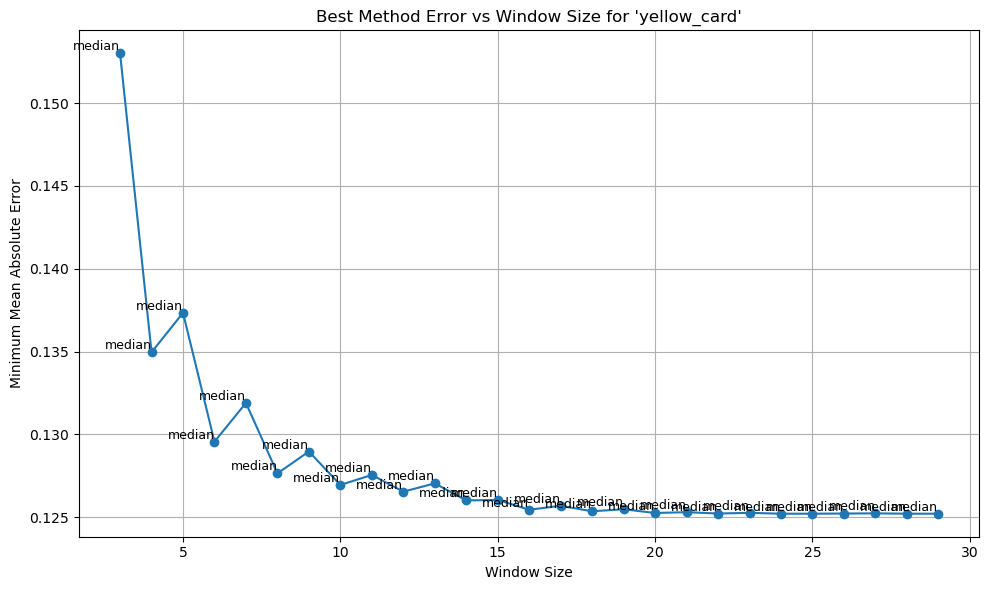

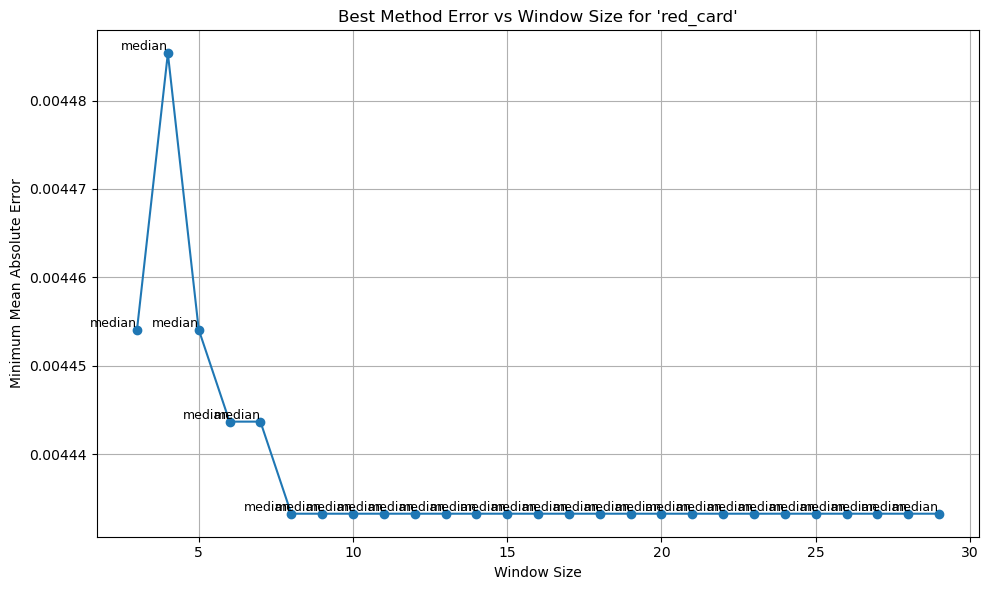

In [197]:
# --- Collect and combine all errors ---
all_errors = []
for window, df in aggregated_dfs.items():
    error_df = error_analysis(df, features_to_aggregate, methods)
    error_df['window'] = window
    all_errors.append(error_df)

error_window_df = pd.concat(all_errors, ignore_index=True)
# Find best method per window per feature
best_errors = (
    error_window_df
    .sort_values(by="mean_error")
    .groupby(["feature", "window"])
    .first()
    .reset_index()
)

# Plotting
for feature in features_to_aggregate:
    subset = best_errors[best_errors["feature"] == feature]
    plt.figure(figsize=(10, 6))
    plt.plot(subset["window"], subset["mean_error"], marker='o')
    
    # Annotate each point with the best method
    for _, row in subset.iterrows():
        plt.text(row["window"], row["mean_error"], row["method"], fontsize=9, ha='right', va='bottom')
    
    plt.title(f"Best Method Error vs Window Size for '{feature}'")
    plt.xlabel("Window Size")
    plt.ylabel("Minimum Mean Absolute Error")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [198]:
aggregated_dfs[9][["key_passes_mean", "key_passes_mean_error", "key_passes"]]

,key_passes_mean,key_passes_mean_error,key_passes
0,0.0,0.0,0
1,0.0,1.0,1
2,0.0,0.0,0
3,0.0,0.0,0
4,0.0,0.0,0
...,...,...,...
96086,0.0,0.0,0
96087,0.0,0.0,0
96088,0.0,0.0,0
96089,2.0,2.0,0


In [209]:
feature_to_window_and_method = {
    "shots": [15, "median"],
    "xG": [15, "median"],
    "key_passes": [15, "median"],
    "xA": [15, "median"],
    "xGChain": [15, "median"],
    "xGBuildup": [15, "median"],
    "yellow_card": [15, "median"],
    "red_card": [8, "median"]
} 

In [210]:
def merge_aggregated_data(base_df, aggregated_dfs, feature_to_window_and_method):
    """
    Merge aggregated feature values and their errors into the base DataFrame 
    without renaming the original columns.
    """
    df = base_df.copy()

    for feature, (window, method) in feature_to_window_and_method.items():
        if window not in aggregated_dfs:
            print(f"[WARN] Window {window} not found for feature '{feature}'. Skipping.")
            continue
        
        agg_df = aggregated_dfs[window]
        agg_col = f"{feature}_{method}"
        error_col = f"{agg_col}_error"

        # Column validation
        if agg_col not in agg_df.columns or error_col not in agg_df.columns:
            print(f"[WARN] Missing columns for '{feature}' with window {window} and method '{method}'. Skipping.")
            continue

        # Merge into main DataFrame (keeping original names)
        df = df.merge(
            agg_df[['player_id', 'date', agg_col, error_col]],
            on=['player_id', 'date'],
            how='left'
        )

    return df


In [211]:
df_to_save= merge_aggregated_data(roster_df, aggregated_dfs, feature_to_window_and_method)

In [212]:
df_to_save.columns

Index(['goals', 'own_goals', 'shots', 'xG', 'time', 'player_id', 'team_id',
       'position', 'player', 'h_a', 'yellow_card', 'red_card', 'key_passes',
       'assists', 'xA', 'xGChain', 'xGBuildup', 'positionOrder', 'match_link',
       'id', 'date', 'shots_median', 'shots_median_error', 'xG_median',
       'xG_median_error', 'key_passes_median', 'key_passes_median_error',
       'xA_median', 'xA_median_error', 'xGChain_median',
       'xGChain_median_error', 'xGBuildup_median', 'xGBuildup_median_error',
       'yellow_card_median', 'yellow_card_median_error', 'red_card_median',
       'red_card_median_error'],
      dtype='object')

In [213]:
df_to_save.to_csv('Data/understat_roster_aggregated.csv', index=False)